# Machine Learning Pipeline
Use this notebook as a template to explore different OSDR datasets, machine learning algorithms, transformations, and feature counts.  Results are saved in your Google Drive at the end of the notebook.

Uncomment the first configuration and run the notebook by clicking "Run all". You'll be prompted to access your Google Drive in 2 dialogs. After approving that access, let the notebook run to completion.  Go through the notebook plots and determine:
1. DESeq2 differentially expressed genes
2. ML algorithms predictive (most important) genes
3. DESeq2 and ML intersection genes
4. Functional enrichment by DESeq2, ML, and intersecting genes
5. All results were stored in Google Drive
6. Length of time for running notebook per run

Repeat the above steps for the second configuration.


In [1]:
# select the configuration


## Prepare runtime environment for lab

In [2]:
# mount google drive to mnt mount point
'''from google.colab import drive
drive.flush_and_unmount()
drive.mount("mnt")'''


'from google.colab import drive\ndrive.flush_and_unmount()\ndrive.mount("mnt")'

In [3]:
# time the notebook
import datetime
start_time = datetime.datetime.now()
print('notebook start time: ', start_time.strftime('%Y-%m-%d %H:%M:%S'))

notebook start time:  2026-10-24 22:19:56


In [4]:
import requests
import json
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

ORCHESTRATION_URL = "http://127.0.0.1:8000"
API_ENDPOINT = f"{ORCHESTRATION_URL}/api/pipeline/run"
OUTPUT_DIR="/content/mnt/MyDrive/SJSU/2026/MLPIPE/" + timestamp
if not os.path.exists(OUTPUT_DIR):
  !mkdir -p {OUTPUT_DIR}
print(f"✓ Configured to use: {API_ENDPOINT}")


mkdir: /content: Read-only file system
✓ Configured to use: http://127.0.0.1:8000/api/pipeline/run


## Configure and Run Pipeline

In [5]:
# Define pipeline payload directly
payload = {
    #"osd_ids": "47,48,137,168",
    "osd_ids": "101,103,104,105,111",
    "config": {
        "target_column": "Factor Value[Spaceflight]",
        "task_type": "classification",
        "trans_list": "s,l",  # s=standardize, l=log transform
        "ensemble_algorithms": ["random_forest", "logistic_regression", "xgboost", "svm", "neural_network"],
        "hyperparameters": {},
        "metrics": ["accuracy", "precision", "recall", "f1_score"],
        "test_size": 0.2,
        "random_state": 42,
        "min_features": 1000,
        "factor_name": "Factor Value[Spaceflight]",
        "factor_values": ["Ground Control", "Space Flight"],
        "fi_methods": ["permutation", "recursive"],
        #"fi_methods": ["permutation"],
        "convert_ensembl_to_symbol": True,
        "coding_only": True,
        "keep_biotypes": ["protein_coding", "lncRNA"],
        "enrichment": {
            "enabled": True,
            "methods": ["ora", "gsea"],          # either or both
            "ontologies": ["BP"],                # GO "BP", "MF", "CC"
            "ora_lists": ["ml_consensus", "deseq2_significant", "overlap"],   # also "deseq2_up", "deseq2_down"
            "gsea_rankings": ["deseq2", "ml_importance"],
            "organism": "auto",                  # or "mmu" / "hsa"
            "p_adjust_method": "BH",
            "padj_cutoff": 0.05,                 # adjusted p-value cutoff
            "qvalue_cutoff": 0.2,                # ORA q-value cutoff (clusterProfiler default)
            "min_gs_size": 10,
            "max_gs_size": 500,
            "simplify": True,                    # merge near-duplicate GO terms
            "simplify_cutoff": 0.7,
            "top_n_terms": 20,
        },
    }
}

print("Pipeline Configuration:")
print(f"  OSD IDs: {payload['osd_ids']}")
for key, value in payload['config'].items():
    print(f"  {key}: {value}")

Pipeline Configuration:
  OSD IDs: 101,103,104,105,111
  target_column: Factor Value[Spaceflight]
  task_type: classification
  trans_list: s,l
  ensemble_algorithms: ['random_forest', 'logistic_regression', 'xgboost', 'svm', 'neural_network']
  hyperparameters: {}
  metrics: ['accuracy', 'precision', 'recall', 'f1_score']
  test_size: 0.2
  random_state: 42
  min_features: 1000
  factor_name: Factor Value[Spaceflight]
  factor_values: ['Ground Control', 'Space Flight']
  fi_methods: ['permutation', 'recursive']
  convert_ensembl_to_symbol: True
  coding_only: True
  keep_biotypes: ['protein_coding', 'lncRNA']
  enrichment: {'enabled': True, 'methods': ['ora', 'gsea'], 'ontologies': ['BP'], 'ora_lists': ['ml_consensus', 'deseq2_significant', 'overlap'], 'gsea_rankings': ['deseq2', 'ml_importance'], 'organism': 'auto', 'p_adjust_method': 'BH', 'padj_cutoff': 0.05, 'qvalue_cutoff': 0.2, 'min_gs_size': 10, 'max_gs_size': 500, 'simplify': True, 'simplify_cutoff': 0.7, 'top_n_terms': 20}


## Execute Pipeline

In [6]:
import time
from datetime import datetime


def _print_events(events):
    for ev in events:
        print(f"[{ev.get('progress_percent', 0):3d}%] {ev.get('status', '')}: {ev.get('message', '')}")
        if ev.get("status") == "failed" and ev.get("error"):
            print(f"      error: {ev['error']}")


def wait_for_pipeline(pipeline_id, poll_seconds=5, since=0):
    """Follow a run until it finishes. Survives dropped connections; safe to call again later."""
    global result, LAST_PIPELINE_ID
    LAST_PIPELINE_ID = pipeline_id
    url = f"{ORCHESTRATION_URL}/api/pipeline/jobs/{pipeline_id}"
    failures = 0
    try:
        while True:
            try:
                r = requests.get(url, params={"since": since}, timeout=30)
                if r.status_code == 404:
                    print(f"\n✗ The backend doesn't know run {pipeline_id} (it was restarted, or the run expired).")
                    return None
                r.raise_for_status()
                snap = r.json()
                if failures:
                    print("  ...reconnected")
                failures = 0
            except requests.exceptions.RequestException as e:
                failures += 1
                wait = min(60, poll_seconds * 2 ** min(failures, 4))
                print(f"  (connection problem: {type(e).__name__}; the run continues on the server. Retrying in {wait}s)")
                time.sleep(wait)
                continue

            _print_events(snap["events"])
            since = snap["next_since"]
            _log = globals().get("run_log")
            if _log is not None:
                _log["errors"].extend(e.get("error") for e in snap["events"] if e.get("error"))
            if snap["status"] == "completed":
                print(f"\n✓ Pipeline completed in {snap['elapsed_seconds'] // 60} min {snap['elapsed_seconds'] % 60} s")
                result = snap["result"]
                if _log is not None:
                    _log["finished"] = datetime.now().isoformat(timespec="seconds")
                return result
            if snap["status"] == "failed":
                print(f"\n✗ Pipeline failed: {snap.get('error')}")
                result = None
                return None
            time.sleep(poll_seconds)
    except KeyboardInterrupt:
        print(f"\nStopped watching. The run keeps going on the server. To pick it up again:\n"
              f"    result = wait_for_pipeline('{pipeline_id}')")
        return None


def run_pipeline(payload):
    """Start a run on the backend and follow it."""
    config = payload["config"]
    print(f"Starting run on OSD {payload.get('osd_ids')} with {', '.join(config['ensemble_algorithms'])}")
    r = requests.post(f"{ORCHESTRATION_URL}/api/pipeline/jobs", json=payload, timeout=30)
    if r.status_code != 200:
        print(f"✗ The backend rejected the request ({r.status_code}): {r.text[:500]}")
        return None
    pipeline_id = r.json()["pipeline_id"]
    if "run_log" in globals():
        run_log.update({"osd_ids": payload.get("osd_ids"), "config": config, "pipeline_id": pipeline_id,
                        "started": datetime.now().isoformat(timespec="seconds")})
    print(f"Run id: {pipeline_id}")
    print("If you lose the connection or interrupt this cell, the run continues; "
          "resume with  result = wait_for_pipeline(LAST_PIPELINE_ID)\n")
    return wait_for_pipeline(pipeline_id)


result = run_pipeline(payload)

Starting run on OSD 101,103,104,105,111 with random_forest, logistic_regression, xgboost, svm, neural_network
Run id: c2080769-0199-4f68-8e56-187eb2abce74
If you lose the connection or interrupt this cell, the run continues; resume with  result = wait_for_pipeline(LAST_PIPELINE_ID)

[  1%] starting: Pipeline started
[  3%] downloading: Downloading 5 OSDR studies: OSD-101, OSD-103, OSD-104, OSD-105, OSD-111 (first time can take a while)...
[ 15%] downloading: Downloaded 4 studies; combining...
[ 20%] downloading: Studies combined
[ 22%] filtering: Keeping only protein_coding, lncRNA genes...
[ 24%] filtering: Kept 33,113 of 57,186 genes (removed 9326 processed_pseudogene, 3220 TEC, 2201 miRNA, 2142 unprocessed_pseudogene, …)
[ 25%] filtering: Filtering features by CV...
[ 30%] filtering: Filtered to 1001 features
[ 32%] converting: Converting feature names...
[ 33%] converting: Converted 999 Ensembl IDs to gene symbols
[ 35%] training: Training 5 models: random_forest, logistic_regressi

## Display Results

In [7]:
if result:
    print("\\n" + "="*80)
    print("PIPELINE RESULTS - ENSEMBLE TRAINING")
    print("="*80)

    cfg = result.get('config', {})
    print(f"\\nConfiguration:")
    print(f"  Algorithms: {', '.join(cfg.get('algorithms', []))}")
    print(f"  Target: {cfg.get('target_column')}")
    print(f"  OSD IDs: {cfg.get('osd_ids')}")
    print(f"  Test Size: {cfg.get('test_size')}")
    print(f"  Min Features: {cfg.get('min_features')}")

    train = result.get('training_results', {})
    test_metrics = train.get('test_metrics', {})

    print(f"\\nEnsemble Training Results:")
    print(f"  Total Models: {test_metrics.get('num_models', 0)}")
    print(f"  Mean Accuracy: {test_metrics.get('mean_accuracy', 0):.4f}")

    models = test_metrics.get('models', [])
    if models:
        print(f"\\n  Individual Model Performance:")
        for model in models:
            algo = model.get('algorithm', 'unknown')
            acc = model.get('accuracy', 0)
            prec = model.get('precision', 0)
            rec = model.get('recall', 0)
            f1 = model.get('f1_score', 0)
            print(f"    {algo:20s} → Acc: {acc:.4f}, Prec: {prec:.4f}, Rec: {rec:.4f}, F1: {f1:.4f}")

    # Feature importance summary
    fi = result.get('feature_importance', {})
    if fi:
        print(f"\\n  Feature Importance:")
        print(f"    Models with importance: {len(fi)}")
        for model_id in list(fi.keys())[:3]:
            methods = fi[model_id]
            print(f"    {model_id}: {len(methods)} methods computed")
else:
    print("Run pipeline first")

\n================================================================================
PIPELINE RESULTS - ENSEMBLE TRAINING
\nConfiguration:
  Algorithms: random_forest, logistic_regression, xgboost, svm, neural_network
  Target: Factor Value[Spaceflight]
  OSD IDs: 101,103,104,105,111
  Test Size: 0.2
  Min Features: 1000
\nEnsemble Training Results:
  Total Models: 5
  Mean Accuracy: 1.0000
\n  Individual Model Performance:
    random_forest        → Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000
    logistic_regression  → Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000
    xgboost              → Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000
    svm                  → Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000
    neural_network       → Acc: 1.0000, Prec: 1.0000, Rec: 1.0000, F1: 1.0000
\n  Feature Importance:
    Models with importance: 5
    model_797d06756950: 2 methods computed
    model_c1ef958384b4: 2 methods computed
    model_0371279f7554: 2 methods computed


## Visualize Ensemble Model Performance

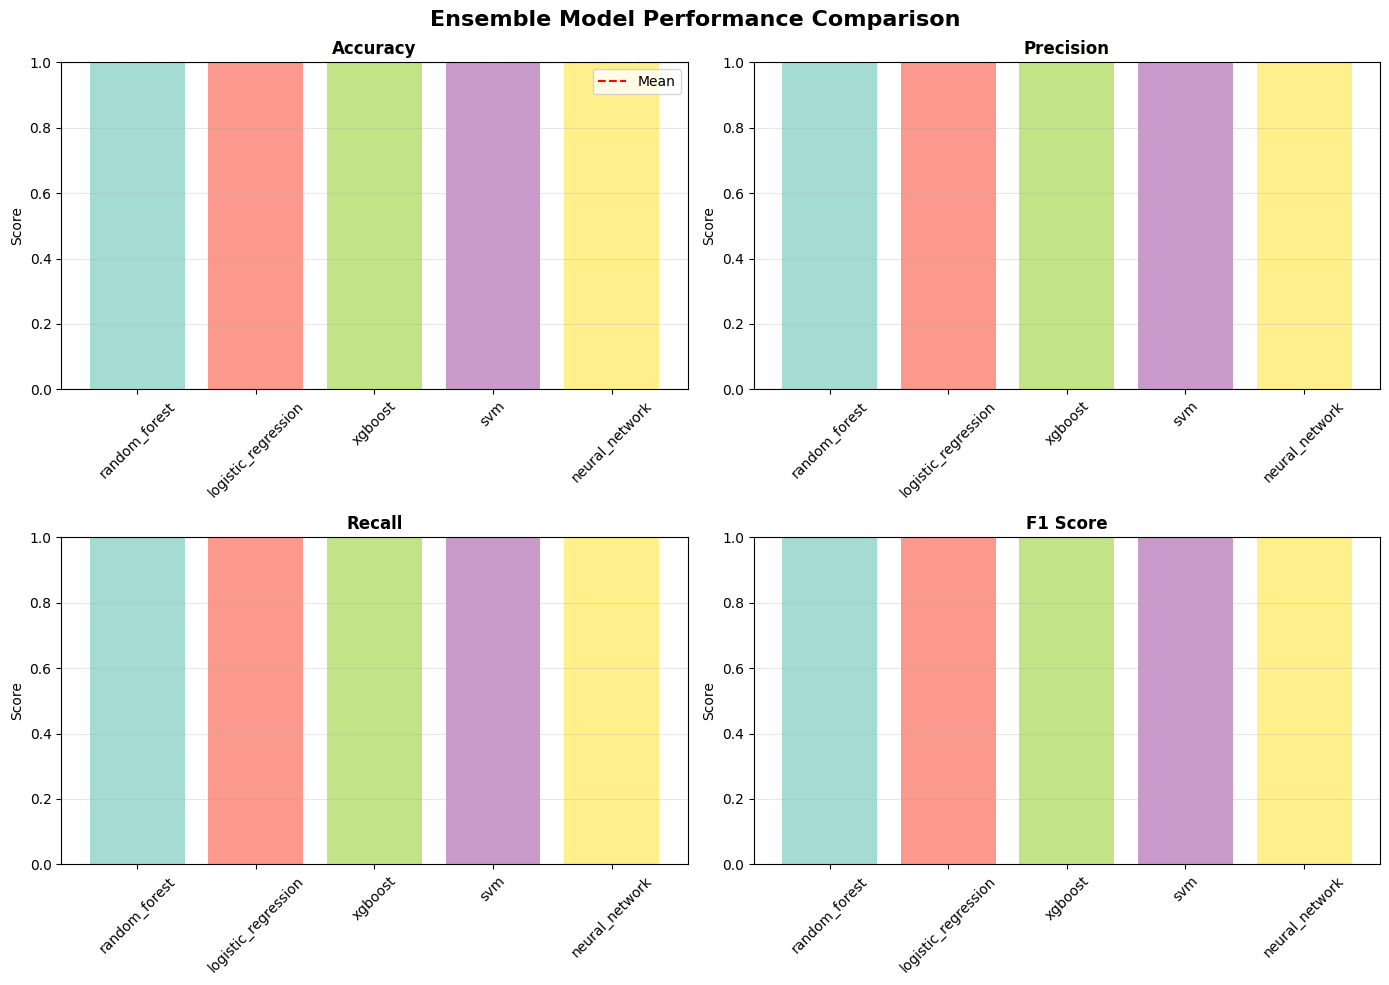

\nModel Ranking (by Accuracy):
                Algorithm  Accuracy  Precision  Recall   F1
Rank                                                       
1           random_forest       1.0        1.0     1.0  1.0
2     logistic_regression       1.0        1.0     1.0  1.0
3                 xgboost       1.0        1.0     1.0  1.0
4                     svm       1.0        1.0     1.0  1.0
5          neural_network       1.0        1.0     1.0  1.0


In [8]:
if result:
    train = result.get('training_results', {})
    test_metrics = train.get('test_metrics', {})
    models = test_metrics.get('models', [])

    if models and len(models) > 0:
        # Extract metrics for each model
        model_names = [m.get('algorithm', 'unknown') for m in models]
        accuracies = [m.get('accuracy', 0) for m in models]
        precisions = [m.get('precision', 0) for m in models]
        recalls = [m.get('recall', 0) for m in models]
        f1_scores = [m.get('f1_score', 0) for m in models]

        # Create comparison plot
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle('Ensemble Model Performance Comparison', fontsize=16, fontweight='bold')

        # Accuracy
        colors = plt.cm.Set3(np.linspace(0, 1, len(model_names)))
        axes[0, 0].bar(model_names, accuracies, color=colors, alpha=0.8)
        axes[0, 0].set_title('Accuracy', fontsize=12, fontweight='bold')
        axes[0, 0].set_ylabel('Score')
        axes[0, 0].set_ylim([0, 1])
        axes[0, 0].grid(axis='y', alpha=0.3)
        axes[0, 0].axhline(y=test_metrics.get('mean_accuracy', 0.5), color='red', linestyle='--', label='Mean')
        axes[0, 0].legend()
        axes[0, 0].tick_params(axis='x', rotation=45)

        # Precision
        axes[0, 1].bar(model_names, precisions, color=colors, alpha=0.8)
        axes[0, 1].set_title('Precision', fontsize=12, fontweight='bold')
        axes[0, 1].set_ylabel('Score')
        axes[0, 1].set_ylim([0, 1])
        axes[0, 1].grid(axis='y', alpha=0.3)
        axes[0, 1].tick_params(axis='x', rotation=45)

        # Recall
        axes[1, 0].bar(model_names, recalls, color=colors, alpha=0.8)
        axes[1, 0].set_title('Recall', fontsize=12, fontweight='bold')
        axes[1, 0].set_ylabel('Score')
        axes[1, 0].set_ylim([0, 1])
        axes[1, 0].grid(axis='y', alpha=0.3)
        axes[1, 0].tick_params(axis='x', rotation=45)

        # F1 Score
        axes[1, 1].bar(model_names, f1_scores, color=colors, alpha=0.8)
        axes[1, 1].set_title('F1 Score', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylabel('Score')
        axes[1, 1].set_ylim([0, 1])
        axes[1, 1].grid(axis='y', alpha=0.3)
        axes[1, 1].tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

        # Model ranking table
        ranking_df = pd.DataFrame({
            'Algorithm': model_names,
            'Accuracy': accuracies,
            'Precision': precisions,
            'Recall': recalls,
            'F1': f1_scores
        }).sort_values('Accuracy', ascending=False).reset_index(drop=True)

        ranking_df.index = ranking_df.index + 1
        ranking_df.index.name = 'Rank'
        print("\\nModel Ranking (by Accuracy):")
        print(ranking_df.to_string())
    else:
        print("No model metrics available")
else:
    print("Run pipeline first")

## Confusion Matrices

Uses the confusion matrices returned by the ML service (`confusion_matrix` in each model's test metrics)
when they're present. If the service doesn't return them yet, set `RECOMPUTE_CM_LOCALLY = True` to rebuild
them here with stratified cross-validation on the dataset pulled from the data service. That needs the
`data_client.py` from one of the services importable from this notebook.

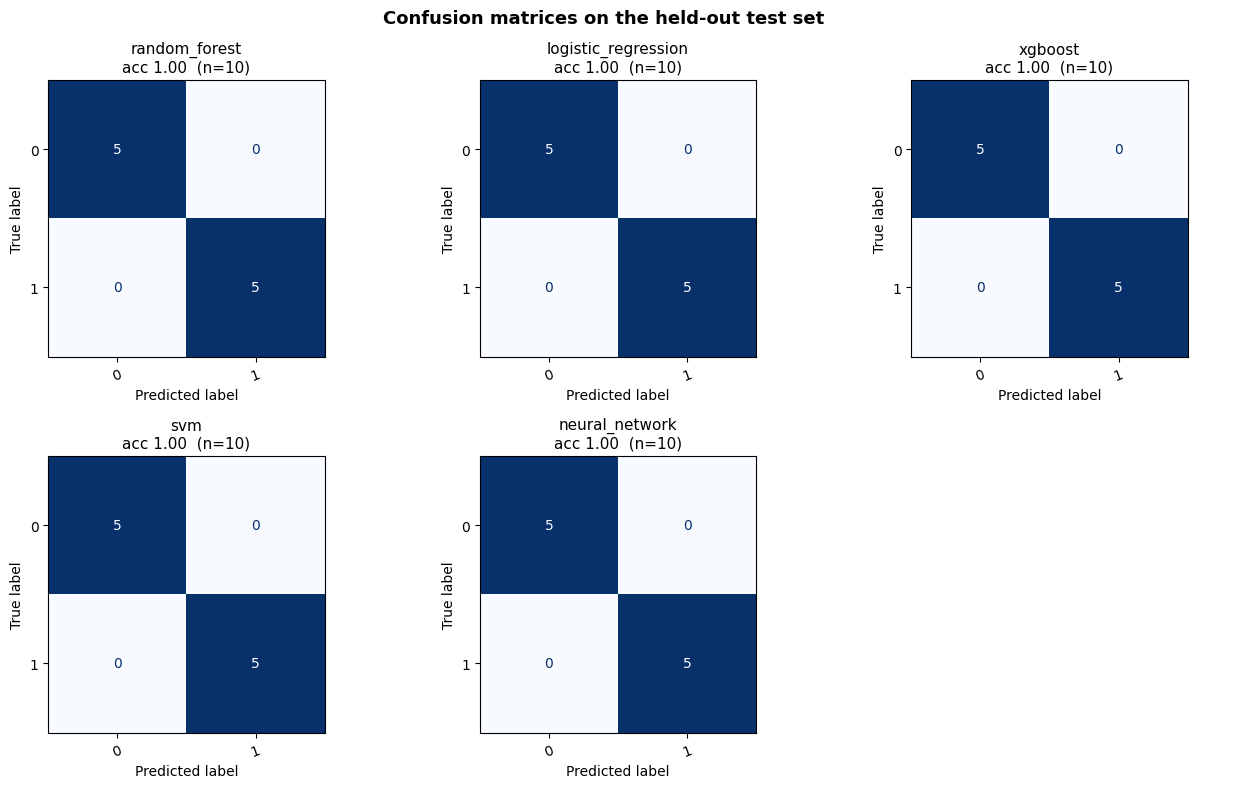

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

RECOMPUTE_CM_LOCALLY = False          # fallback when the service doesn't return confusion matrices
CM_DATASET_ID = "symbols_filtered"    # dataset the models were trained on (for the local fallback)
DATA_SERVICE_URL = "localhost:50051"
CM_LABELS = payload["config"].get("factor_values") or None


def plot_confusion_matrices(matrices, labels, title):
    """matrices: dict {name: 2D array}"""
    n = len(matrices)
    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.0 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, cm) in zip(axes, matrices.items()):
        cm = np.asarray(cm)
        acc = np.trace(cm) / cm.sum() if cm.sum() else 0
        disp_labels = labels if labels and len(labels) == cm.shape[0] else None
        ConfusionMatrixDisplay(cm, display_labels=disp_labels).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"{name}\nacc {acc:.2f}  (n={int(cm.sum())})", fontsize=11)
        ax.tick_params(axis="x", labelrotation=20)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()


def local_cv_confusion_matrices(dataset_id, algorithms, target_col, labels):
    """Fallback: cross-validated predictions for each algorithm + majority vote."""
    import sys
    from pathlib import Path
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import SVC

    for sub in ("feature_importance_service/src", "ml_service/src", "bioinformatics_service/src"):
        p = Path.cwd() / sub
        if (p / "data_client.py").exists():
            sys.path.insert(0, str(p))
            break
    from data_client import DataServiceClient

    client = DataServiceClient(service_url=DATA_SERVICE_URL)
    loader = next(getattr(client, m) for m in ("get_dataset", "load_dataset", "fetch_dataset", "stream_dataset")
                  if hasattr(client, m))
    df = loader(dataset_id)
    y = df[target_col].astype(str).values
    X = df.drop(columns=[target_col]).select_dtypes(include="number")

    try:
        from xgboost import XGBClassifier
        from sklearn.preprocessing import LabelEncoder
        xgb = XGBClassifier(eval_metric="logloss", random_state=42)
    except ImportError:
        xgb = GradientBoostingClassifier(random_state=42)

    zoo = {
        "random_forest": RandomForestClassifier(n_estimators=300, random_state=42),
        "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        "xgboost": xgb,
        "svm": make_pipeline(StandardScaler(), SVC()),
    }
    labels = labels or sorted(set(y))
    n_splits = min(5, pd.Series(y).value_counts().min())
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    preds = {}
    for algo in algorithms:
        if algo not in zoo:
            print(f"  skipping {algo}: no local equivalent")
            continue
        model = zoo[algo]
        if algo == "xgboost" and type(model).__name__ == "XGBClassifier":
            y_num = pd.Series(y).map({lab: i for i, lab in enumerate(labels)}).values
            preds[algo] = np.array(labels)[cross_val_predict(model, X, y_num, cv=cv)]
        else:
            preds[algo] = cross_val_predict(model, X, y, cv=cv)
    votes = pd.DataFrame(preds)
    preds["ensemble (majority vote)"] = votes.apply(
        lambda row: max(labels, key=lambda lab: (row == lab).sum()), axis=1).values
    return {name: confusion_matrix(y, p, labels=labels) for name, p in preds.items()}, labels, n_splits


if result:
    models = result.get("training_results", {}).get("test_metrics", {}).get("models", [])
    returned = {m.get("algorithm", f"model_{i}"): m["confusion_matrix"]
                for i, m in enumerate(models) if m.get("confusion_matrix") is not None}

    if returned:
        labels = next((m.get("labels") or m.get("class_labels") for m in models if m.get("labels") or m.get("class_labels")),
                      CM_LABELS)
        plot_confusion_matrices(returned, labels, "Confusion matrices on the held-out test set")
    elif RECOMPUTE_CM_LOCALLY:
        algos = payload["config"]["ensemble_algorithms"]
        target = payload["config"]["target_column"]
        mats, labels, k = local_cv_confusion_matrices(CM_DATASET_ID, algos, target, CM_LABELS)
        plot_confusion_matrices(mats, labels, f"Cross-validated confusion matrices ({k}-fold, {CM_DATASET_ID})")
    else:
        print("The ML service didn't return confusion matrices.")
        print("Either add 'confusion_matrix' to each model's test metrics in the ML service,")
        print("or set RECOMPUTE_CM_LOCALLY = True above to rebuild them here with cross-validation.")
else:
    print("Run pipeline first")

## Visualize Feature Importance

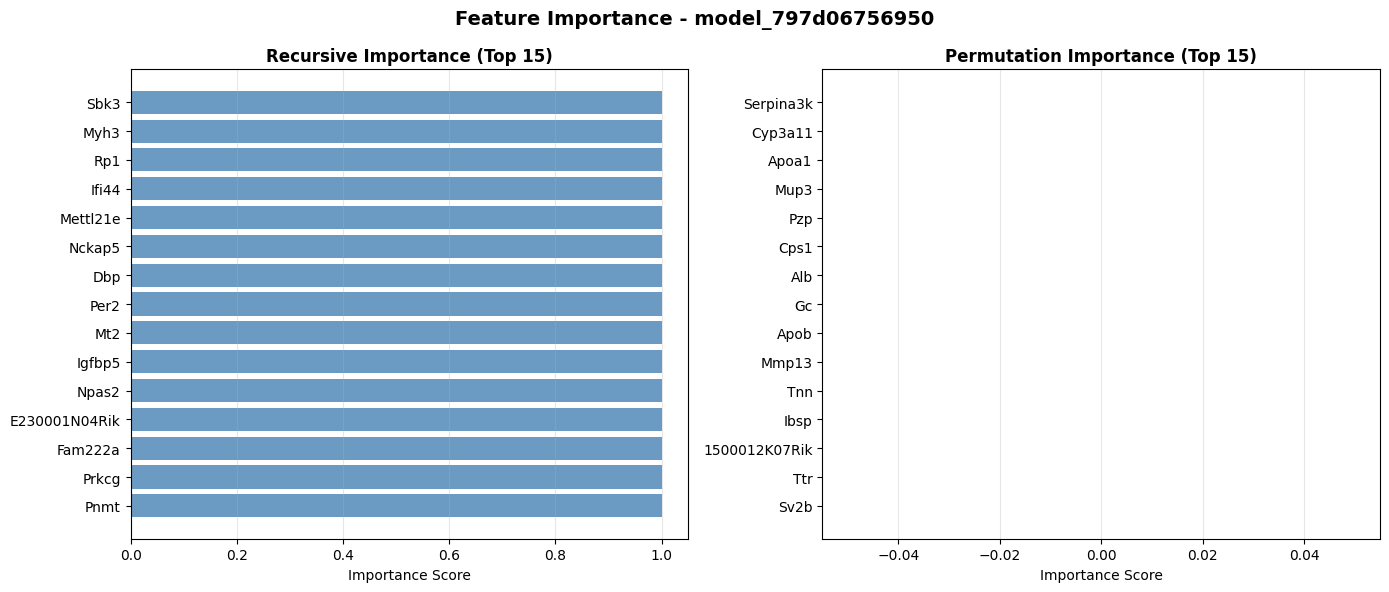

In [10]:
if result:
    fi_data = result.get('feature_importance', {})

    if fi_data:
        # Get first model's importance data
        first_model_id = list(fi_data.keys())[0] if fi_data else None

        if first_model_id:
            model_importance = fi_data[first_model_id]

            # Create subplot for each method
            methods = list(model_importance.keys())
            num_methods = len(methods)

            fig, axes = plt.subplots(1, min(num_methods, 2), figsize=(14, 6))
            if num_methods == 1:
                axes = [axes]

            fig.suptitle(f'Feature Importance - {first_model_id}', fontsize=14, fontweight='bold')

            for idx, method in enumerate(methods[:2]):
                if idx >= len(axes):
                    break

                features_data = model_importance.get(method, {}).get('features', [])

                if features_data:
                    # Get top 15 features
                    top_features = sorted(features_data, key=lambda x: x.get('importance', 0), reverse=True)[:15]

                    feature_names = [f.get('feature_name', 'unknown') for f in top_features]
                    importances = [f.get('importance', 0) for f in top_features]

                    # Plot
                    axes[idx].barh(feature_names, importances, color='steelblue', alpha=0.8)
                    axes[idx].set_title(f'{method.capitalize()} Importance (Top 15)', fontweight='bold')
                    axes[idx].set_xlabel('Importance Score')
                    axes[idx].invert_yaxis()
                    axes[idx].grid(axis='x', alpha=0.3)

            plt.tight_layout()
            plt.show()

    else:
        print("No feature importance data available")
else:
    print("Run pipeline first")

## DESeq2 Differential Expression Analysis

In [11]:
if result:
    deseq2 = result.get('deseq2_results', {})

    if deseq2.get('success'):
        print(f"\nDESeq2 Analysis Results:")
        print(f"  Analysis ID: {deseq2.get('analysis_id')}")
        print(f"  Total genes analyzed: {deseq2.get('num_genes')}")
        print(f"  Significant genes (padj < 0.05): {deseq2.get('num_significant')}")
        print(f"    - Upregulated: {deseq2.get('num_upregulated')}")
        print(f"    - Downregulated: {deseq2.get('num_downregulated')}")

        # Top differential genes table
        #diff_genes = deseq2.get('differential_genes', [])
        diff_genes = [g for g in deseq2.get('differential_genes', []) if g['padj'] < 0.05]
        if diff_genes:
            top_genes = sorted(diff_genes, key=lambda x: abs(x.get('log2_fold_change', 0)), reverse=True)[:10]

            deseq_df = pd.DataFrame({
                'Gene ID': [g['gene_id'] for g in top_genes],
                'Log2FC': [g['log2_fold_change'] for g in top_genes],
                'P-value': [g['pvalue'] for g in top_genes],
                'Padj': [g['padj'] for g in top_genes],
                'BaseMean': [g['base_mean'] for g in top_genes]
            })

            print(f"\nTop 10 Differentially Expressed Genes:")
            print(deseq_df.to_string(index=False))
    else:
        error = deseq2.get('error', 'Unknown error')
        print(f"DESeq2 analysis failed: {error}")
else:
    print("Run pipeline first")


DESeq2 Analysis Results:
  Analysis ID: deseq2_symbols_d9a73f5c3e77
  Total genes analyzed: 1000
  Significant genes (padj < 0.05): 4
    - Upregulated: 1
    - Downregulated: 3

Top 10 Differentially Expressed Genes:
      Gene ID    Log2FC      P-value         Padj    BaseMean
1500012K07Rik -2.713848 2.107924e-04 2.602375e-03   27.410785
         Sv2b -2.342111 9.606078e-07 3.001899e-05  124.714292
        Mylk3 -2.124909 4.305889e-05 6.944983e-04   94.840130
          Dbp  2.024601 7.539441e-18 2.513147e-15 2288.124820
        Ciart  1.945807 9.453362e-09 4.726681e-07  297.062462
         Sbk3 -1.824782 3.495467e-04 4.035174e-03  258.366044
         Fosb -1.783318 7.772249e-10 4.571911e-08  135.272756
     Mettl21e -1.753354 1.904594e-11 1.190371e-09  429.539305
         Per2  1.718710 5.040151e-12 3.360101e-10  501.596309
          Mt2 -1.539564 4.099951e-12 2.928536e-10  331.641498


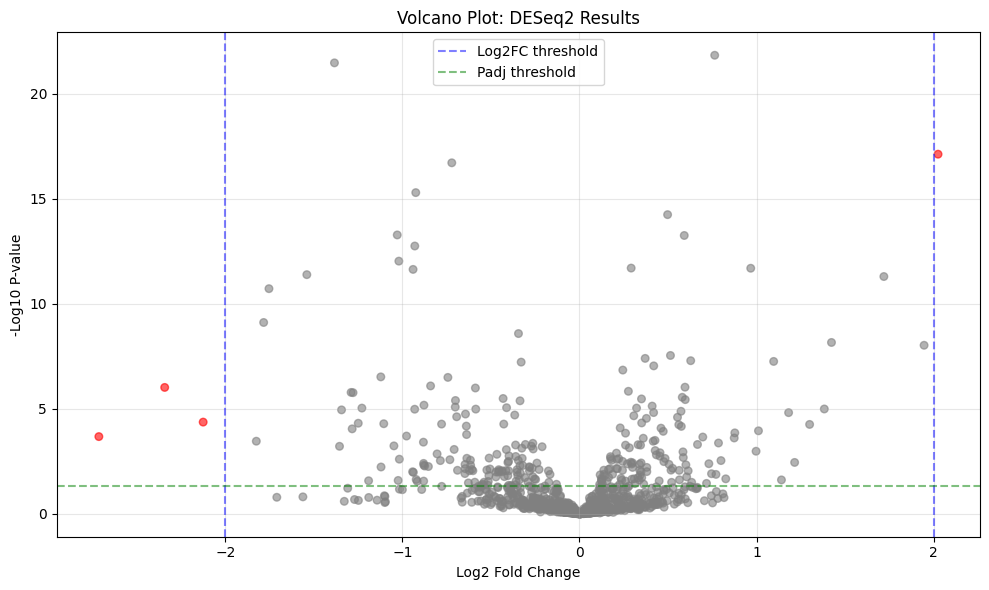

In [12]:
if result:
    deseq2 = result.get('deseq2_results', {})

    if deseq2.get('success'):
        diff_genes = deseq2.get('differential_genes', [])
        if diff_genes:
            fig, ax = plt.subplots(figsize=(10, 6))
            log2fc = [g['log2_fold_change'] for g in diff_genes]
            neg_log10_pval = [-np.log10(max(g['pvalue'], 1e-300)) for g in diff_genes]

            # Color by significance
            colors = ['red' if g['padj'] < 0.05 and abs(g['log2_fold_change']) > 2 else 'gray' for g in diff_genes]

            ax.scatter(log2fc, neg_log10_pval, c=colors, alpha=0.6, s=30)
            ax.axvline(x=2, color='blue', linestyle='--', alpha=0.5, label='Log2FC threshold')
            ax.axvline(x=-2, color='blue', linestyle='--', alpha=0.5)
            ax.axhline(y=-np.log10(0.05), color='green', linestyle='--', alpha=0.5, label='Padj threshold')

            ax.set_xlabel('Log2 Fold Change')
            ax.set_ylabel('-Log10 P-value')
            ax.set_title('Volcano Plot: DESeq2 Results')
            ax.legend()
            ax.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()
else:
    print("Run pipeline first")

## Ensemble Consensus Genes

For each model, genes are ranked by each feature-importance method the model supports (SVM has no RFE),
and the method ranks are averaged. A gene gets one vote from each model that puts it in its top `TOP_N`.
Consensus genes are those with votes from a simple majority of models (`MIN_VOTES`).

In [13]:
TOP_N = 50                  # top genes per model
MIN_VOTES = None            # None = simple majority of models
MODEL_NAMES = {}            # optional {model_id: "random_forest", ...} for nicer labels


def model_rankings(fi_data):
    """{model_id: Series(gene -> mean rank across methods)}"""
    out = {}
    for model_id, methods in fi_data.items():
        ranks = []
        for method, payload_ in methods.items():
            feats = (payload_ or {}).get("features", [])
            if not feats:
                continue
            df_ = pd.DataFrame(feats)
            if "rank" in df_ and df_["rank"].notna().all() and df_["rank"].nunique() > 1:
                r = df_.set_index("feature_name")["rank"].astype(float)
            else:
                r = df_.set_index("feature_name")["importance"].rank(ascending=False, method="min")
            ranks.append(r.rename(method))
        if ranks:
            out[model_id] = pd.concat(ranks, axis=1).mean(axis=1).sort_values()
    return out


if result and result.get("feature_importance"):
    rankings = model_rankings(result["feature_importance"])
    n_models = len(rankings)
    min_votes = MIN_VOTES or (n_models // 2 + 1)

    top_sets = {MODEL_NAMES.get(m, m): set(r.index[:TOP_N]) for m, r in rankings.items()}
    votes = pd.Series([g for s in top_sets.values() for g in s]).value_counts()
    mean_rank = pd.concat(rankings.values(), axis=1).mean(axis=1)

    consensus_df = (pd.DataFrame({"gene": votes.index, "votes": votes.values})
                    .assign(mean_rank=lambda d: d["gene"].map(mean_rank).round(1))
                    .sort_values(["votes", "mean_rank"], ascending=[False, True])
                    .reset_index(drop=True))
    consensus_genes = consensus_df[consensus_df["votes"] >= min_votes]

    print(f"{n_models} models, top {TOP_N} genes each; consensus = votes >= {min_votes}")
    print(f"Consensus genes: {len(consensus_genes)}")
    print(consensus_df["votes"].value_counts().sort_index(ascending=False)
          .rename_axis("votes").rename("genes").to_string())
    print()
    print(consensus_genes.head(25).to_string(index=False))
else:
    print("Run pipeline first (no feature importance in result)")

5 models, top 50 genes each; consensus = votes >= 3
Consensus genes: 50
votes
5    40
4    10
1    10

         gene  votes  mean_rank
      Cyp3a11      5       14.7
         Mup3      5       15.4
    Serpina3k      5       15.6
          Alb      5       15.9
           Gc      5       16.0
        Mmp13      5       16.2
          Pzp      5       16.4
        Apoa1      5       16.6
1500012K07Rik      5       16.8
         Cps1      5       17.3
         Sv2b      5       17.8
         Ibsp      5       18.2
        Mylk3      5       18.5
         Apob      5       18.8
          Ttr      5       18.9
          Dsp      5       19.3
       Slc4a1      5       19.5
          Tnn      5       20.0
        Tecrl      5       21.5
         Sbk3      5       21.7
          Sln      5       22.3
      Gm12295      5       22.9
        Ces5a      5       23.2
A730036I17Rik      5       23.6
         Myl2      5       23.6


## ML Consensus Genes vs DESeq2

Which consensus genes are also differentially expressed? The hypergeometric p-value asks how likely an
overlap this large would be if the consensus genes were a random draw from the tested genes.

In [14]:
"""
gene_comparison.py

Compare the ML ensemble's consensus important genes against DESeq2
differentially expressed genes (DEGs).

Drop into: orchestration_service/src/gene_comparison.py

Inputs are deliberately flexible:
  consensus_genes : list of gene names, OR dict {gene: votes/score},
                    OR DataFrame with a gene column (+ optional votes/score column)
  deseq2_results  : DataFrame or list of dicts with a gene column plus
                    log2FoldChange and padj columns (common name variants accepted)
  universe        : all genes that were tested (genes in the filtered dataset).
                    Needed for the enrichment p-value; if omitted, the union of
                    the DESeq2 result genes and consensus genes is used.
"""

from __future__ import annotations

import logging
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Union

import pandas as pd
from scipy.stats import hypergeom

logger = logging.getLogger(__name__)

_GENE_COLS = ["gene", "gene_id", "gene_symbol", "symbol", "feature", "feature_name", "name"]
_LFC_COLS = ["log2FoldChange", "log2_fold_change", "log2fc", "l2fc", "lfc"]
_PADJ_COLS = ["padj", "p_adj", "adj_pvalue", "fdr", "qvalue"]
_SCORE_COLS = ["votes", "vote_count", "n_models", "score", "importance", "mean_importance", "consensus_score"]


def _find_col(df: pd.DataFrame, candidates: List[str], required: bool = True) -> Optional[str]:
    lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    if required:
        raise ValueError(f"None of {candidates} found in columns {list(df.columns)}")
    return None


def _normalize_consensus(consensus) -> pd.DataFrame:
    """Return DataFrame[gene, ml_score, ml_rank]."""
    if isinstance(consensus, pd.DataFrame):
        df = consensus.copy()
        gcol = _find_col(df, _GENE_COLS, required=False)
        if gcol is None:  # gene names may be the index
            df = df.reset_index().rename(columns={"index": "gene"})
            gcol = "gene"
        scol = _find_col(df, _SCORE_COLS, required=False)
        out = pd.DataFrame({"gene": df[gcol].astype(str)})
        out["ml_score"] = df[scol].values if scol else range(len(df), 0, -1)
    elif isinstance(consensus, dict):
        out = pd.DataFrame({"gene": [str(g) for g in consensus], "ml_score": list(consensus.values())})
    else:  # ordered iterable, most important first
        genes = [str(g) for g in consensus]
        out = pd.DataFrame({"gene": genes, "ml_score": range(len(genes), 0, -1)})

    out = out.drop_duplicates("gene").sort_values("ml_score", ascending=False).reset_index(drop=True)
    out["ml_rank"] = range(1, len(out) + 1)
    return out


def _normalize_deseq2(deseq2_results) -> pd.DataFrame:
    """Return DataFrame[gene, log2FoldChange, padj] for all tested genes."""
    df = pd.DataFrame(deseq2_results).copy()
    gcol = _find_col(df, _GENE_COLS, required=False)
    if gcol is None:
        df = df.reset_index().rename(columns={"index": "gene"})
        gcol = "gene"
    lfc = _find_col(df, _LFC_COLS)
    padj = _find_col(df, _PADJ_COLS)
    out = pd.DataFrame({
        "gene": df[gcol].astype(str),
        "log2FoldChange": pd.to_numeric(df[lfc], errors="coerce"),
        "padj": pd.to_numeric(df[padj], errors="coerce"),
    })
    return out.drop_duplicates("gene").reset_index(drop=True)


def compare_genes(
    consensus_genes: Union[List[str], Dict[str, float], pd.DataFrame],
    deseq2_results: Union[pd.DataFrame, List[dict]],
    universe: Optional[Iterable[str]] = None,
    padj_threshold: float = 0.05,
    log2fc_threshold: float = 2.0,
    top_n_ml: Optional[int] = None,
    output_dir: Optional[Union[str, Path]] = None,
) -> Dict:
    """
    Compare ML consensus genes with DESeq2 significant genes.

    Returns a dict with:
      overlap, ml_only, deseq2_only : sorted gene lists
      n_ml, n_deseq2, n_overlap, n_universe
      jaccard                       : |A∩B| / |A∪B|
      hypergeom_pvalue              : P(overlap >= observed) by chance
      expected_overlap              : overlap expected by chance
      fold_enrichment               : observed / expected
      table                         : DataFrame, one row per gene in either set
    """
    ml = _normalize_consensus(consensus_genes)
    if top_n_ml is not None:
        ml = ml.head(top_n_ml)
    de = _normalize_deseq2(deseq2_results)

    sig_mask = (de["padj"] < padj_threshold) & (de["log2FoldChange"].abs() > log2fc_threshold)
    deg = de[sig_mask]

    ml_set = set(ml["gene"])
    deg_set = set(deg["gene"])

    if universe is not None:
        universe_set = {str(g) for g in universe}
    else:
        universe_set = set(de["gene"]) | ml_set
        logger.warning("No gene universe supplied; using DESeq2-tested genes ∪ ML genes "
                       f"({len(universe_set)} genes) for the enrichment test.")

    # Genes outside the universe can't be tested; drop them from both sets
    dropped = (ml_set | deg_set) - universe_set
    if dropped:
        logger.warning(f"{len(dropped)} genes not in universe were ignored: {sorted(dropped)[:10]}...")
    ml_set &= universe_set
    deg_set &= universe_set

    overlap = ml_set & deg_set
    union = ml_set | deg_set
    N, K, n, k = len(universe_set), len(deg_set), len(ml_set), len(overlap)

    expected = (n * K / N) if N else 0.0
    pval = float(hypergeom.sf(k - 1, N, K, n)) if N and n and K else 1.0
    jaccard = (k / len(union)) if union else 0.0
    fold = (k / expected) if expected > 0 else float("nan")

    # Merged per-gene table
    table = pd.DataFrame({"gene": sorted(union)})
    table = table.merge(ml[["gene", "ml_rank", "ml_score"]], on="gene", how="left")
    table = table.merge(de, on="gene", how="left")
    table["in_ml"] = table["gene"].isin(ml_set)
    table["in_deseq2"] = table["gene"].isin(deg_set)
    table["category"] = table.apply(
        lambda r: "both" if r.in_ml and r.in_deseq2 else ("ml_only" if r.in_ml else "deseq2_only"), axis=1
    )
    table["direction"] = table["log2FoldChange"].apply(
        lambda x: "up" if pd.notna(x) and x > 0 else ("down" if pd.notna(x) and x < 0 else "")
    )
    cat_order = {"both": 0, "ml_only": 1, "deseq2_only": 2}
    table = table.sort_values(
        by=["category", "ml_rank", "padj"],
        key=lambda s: s.map(cat_order) if s.name == "category" else s,
        na_position="last",
    ).reset_index(drop=True)

    result = {
        "overlap": sorted(overlap),
        "ml_only": sorted(ml_set - deg_set),
        "deseq2_only": sorted(deg_set - ml_set),
        "n_ml": n,
        "n_deseq2": K,
        "n_overlap": k,
        "n_universe": N,
        "jaccard": round(jaccard, 4),
        "expected_overlap": round(expected, 3),
        "fold_enrichment": round(fold, 3) if fold == fold else None,
        "hypergeom_pvalue": pval,
        "padj_threshold": padj_threshold,
        "log2fc_threshold": log2fc_threshold,
        "table": table,
    }

    logger.info(
        f"Gene comparison: ML={n}, DESeq2={K}, overlap={k} "
        f"(expected {expected:.2f}, p={pval:.3g}, Jaccard={jaccard:.3f})"
    )

    if output_dir is not None:
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        table.to_csv(out / "gene_comparison.csv", index=False)
        summary = {k_: v for k_, v in result.items() if k_ != "table"}
        pd.Series(summary).to_json(out / "gene_comparison_summary.json", indent=2)
        logger.info(f"Saved gene comparison to {out}")

    return result


In [15]:



PADJ_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 2.0

deseq2 = result.get("deseq2_results", {}) if result else {}
if result and deseq2.get("success") and "consensus_genes" in globals():
    deseq2_df = pd.DataFrame(deseq2.get("differential_genes", []))

    # Universe = genes both analyses could have picked
    ml_universe = set().union(*[set(r.index) for r in rankings.values()])
    de_universe = set(deseq2_df["gene_id"].astype(str))
    universe = set(deseq2_df["gene_id"].astype(str))   # the genes both methods were given
    #universe = ml_universe & de_universe if len(de_universe) >= 0.9 * deseq2.get("num_genes", 0) else ml_universe
    if len(de_universe) < 0.9 * deseq2.get("num_genes", 0):
        print(f"Note: DESeq2 returned {len(de_universe)} of {deseq2.get('num_genes')} genes; "
              "using the ML feature set as the universe.")

    cmp = compare_genes(consensus_genes, deseq2_df, universe=universe,
                        padj_threshold=PADJ_THRESHOLD, log2fc_threshold=LOG2FC_THRESHOLD)

    print(f"Consensus genes (ML):      {cmp['n_ml']}")
    print(f"DESeq2 significant genes:  {cmp['n_deseq2']}  (padj < {PADJ_THRESHOLD}, |log2FC| > {LOG2FC_THRESHOLD})")
    print(f"Genes tested (universe):   {cmp['n_universe']}")
    print(f"Overlap:                   {cmp['n_overlap']}  (expected by chance {cmp['expected_overlap']})")
    print(f"Fold enrichment:           {cmp['fold_enrichment']}")
    print(f"Hypergeometric p:          {cmp['hypergeom_pvalue']:.3g}")
    print(f"Jaccard:                   {cmp['jaccard']}")
    print(f"\nFound by both: {', '.join(cmp['overlap']) or '(none)'}")

    display(cmp["table"].style.format(
        {"ml_score": "{:.0f}", "log2FoldChange": "{:.2f}", "padj": "{:.2e}"}, na_rep="—"))
else:
    print("Needs a successful pipeline run with DESeq2 results and the consensus cell above.")

Consensus genes (ML):      50
DESeq2 significant genes:  4  (padj < 0.05, |log2FC| > 2.0)
Genes tested (universe):   1000
Overlap:                   3  (expected by chance 0.2)
Fold enrichment:           15.0
Hypergeometric p:          0.000455
Jaccard:                   0.0588

Found by both: 1500012K07Rik, Mylk3, Sv2b


,gene,ml_rank,ml_score,log2FoldChange,padj,in_ml,in_deseq2,category,direction
0,Sv2b,23.000000,5,-2.34,3.00e-05,True,True,both,down
1,1500012K07Rik,30.000000,5,-2.71,2.60e-03,True,True,both,down
2,Mylk3,40.000000,5,-2.12,6.94e-04,True,True,both,down
3,Cyp3a11,1.000000,5,-1.71,4.25e-01,True,False,ml_only,down
4,Gm12295,2.000000,5,1.14,1.07e-01,True,False,ml_only,up
5,A730036I17Rik,3.000000,5,1.21,2.61e-02,True,False,ml_only,up
6,Myl2,4.000000,5,0.82,4.35e-01,True,False,ml_only,up
7,Mup3,5.000000,5,-1.56,4.11e-01,True,False,ml_only,down
8,Myh3,6.000000,5,1.30,8.16e-04,True,False,ml_only,up
9,Unc13d,7.000000,5,1.18,2.77e-04,True,False,ml_only,up


In [16]:
d = result["deseq2_results"]
print({k: v for k, v in d.items() if k != "differential_genes"})
print("differential_genes:", len(d.get("differential_genes", [])))

{'success': True, 'analysis_id': 'deseq2_symbols_d9a73f5c3e77', 'num_genes': 1000, 'num_significant': 4, 'num_upregulated': 1, 'num_downregulated': 3, 'volcano_plot_path': '/app/results/deseq2_symbols_d9a73f5c3e77/volcano_plot.png', 'ma_plot_path': '/app/results/deseq2_symbols_d9a73f5c3e77/ma_plot.png'}
differential_genes: 1000


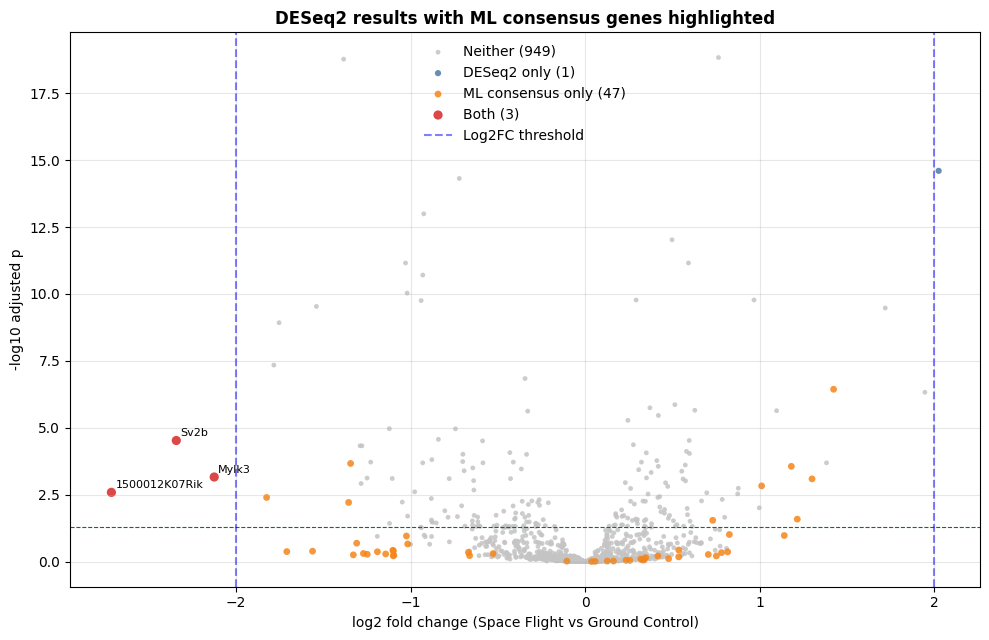

In [17]:
if "cmp" in globals():
    v = deseq2_df.copy()
    v["gene"] = v["gene_id"].astype(str)
    cat = cmp["table"].set_index("gene")["category"]
    v["category"] = v["gene"].map(cat).fillna("neither")
    v["neglog10_padj"] = -np.log10(v["padj"].astype(float).clip(lower=1e-300))

    style = {
        "neither":     dict(color="#c4c4c4", s=12, label="Neither"),
        "deseq2_only": dict(color="#4c78a8", s=20, label="DESeq2 only"),
        "ml_only":     dict(color="#f58518", s=24, label="ML consensus only"),
        "both":        dict(color="#d62728", s=44, label="Both"),
    }
    fig, ax = plt.subplots(figsize=(10, 6.5))
    for c, kw in style.items():
        sub = v[v["category"] == c]
        if len(sub):
            kw = dict(kw)
            ax.scatter(sub["log2_fold_change"], sub["neglog10_padj"], alpha=0.85, edgecolor="none",
                       label=f"{kw.pop('label')} ({len(sub)})", **kw)
    for _, r in v[v["category"] == "both"].nlargest(20, "neglog10_padj").iterrows():
        ax.annotate(r["gene"], (r["log2_fold_change"], r["neglog10_padj"]), fontsize=8,
                    xytext=(3, 3), textcoords="offset points")
    ax.axhline(-np.log10(PADJ_THRESHOLD), ls="--", lw=0.8, color="green")
    ax.axvline(x=2, color='blue', linestyle='--', alpha=0.5, label='Log2FC threshold')
    ax.axvline(x=-2, color='blue', linestyle='--', alpha=0.5)
    fl = payload["config"].get("factor_values") or ["control", "treatment"]
    ax.set_xlabel(f"log2 fold change ({fl[-1]} vs {fl[0]})")
    ax.set_ylabel("-log10 adjusted p")
    ax.set_title("DESeq2 results with ML consensus genes highlighted", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Running GO BP enrichment (ora, gsea) on 1000 background genes. Lists: ml_consensus: 50, deseq2_significant: 4, overlap: 3. Rankings: deseq2, ml_importance.
This can take a few minutes (merging similar GO terms is the slow part)...
✓ Done: 21 enriched terms (organism: mmu)


,analysis,method,ontology,genes in,mapped to GO,terms,note
0,ml_consensus,ora,BP,50,50,13,
1,deseq2_significant,ora,BP,4,4,0,
2,overlap,ora,BP,3,3,0,
3,deseq2,gsea,BP,1000,941,0,
4,ml_importance,gsea,BP,1000,941,8,



ml_consensus — GO:BP  (13 of 13 terms shown)


term_id,description,count,gene_ratio,bg_ratio,padj,genes
GO:0003009,skeletal muscle contraction,6,6/48,11/893,4.55e-03,"Myh3, Tnni1, Tnnc1, Tnnt1, Myh7, Strit1"
GO:0006941,striated muscle contraction,10,10/48,37/893,4.55e-03,"Dsp, Myl2, Myh3, Tnni1, Tnnc1, Tnnt1, Myl3, Atp2a2 … (+2)"
GO:0050879,multicellular organismal movement,6,6/48,13/893,4.97e-03,"Myh3, Tnni1, Tnnc1, Tnnt1, Myh7, Strit1"
GO:0050881,musculoskeletal movement,6,6/48,13/893,4.97e-03,"Myh3, Tnni1, Tnnc1, Tnnt1, Myh7, Strit1"
GO:0055010,ventricular cardiac muscle tissue morphogenesis,6,6/48,14/893,6.11e-03,"Dsp, Myl2, Tnni1, Tnnc1, Myl3, Myh7"
GO:0060048,cardiac muscle contraction,8,8/48,28/893,6.11e-03,"Dsp, Myl2, Tnni1, Tnnc1, Myl3, Atp2a2, Myh7, Strit1"
GO:0090257,regulation of muscle system process,9,9/48,36/893,6.11e-03,"Dsp, Sln, Tnni1, Tnnc1, Tnnt1, Myl3, Atp2a2, Myh7 … (+1)"
GO:0003208,cardiac ventricle morphogenesis,6,6/48,15/893,6.12e-03,"Dsp, Myl2, Tnni1, Tnnc1, Myl3, Myh7"
GO:0014888,striated muscle adaptation,5,5/48,10/893,6.84e-03,"Tnni1, Tnnc1, Tnnt1, Atp2a2, Myh7"
GO:0003229,ventricular cardiac muscle tissue development,6,6/48,16/893,7.83e-03,"Dsp, Myl2, Tnni1, Tnnc1, Myl3, Myh7"


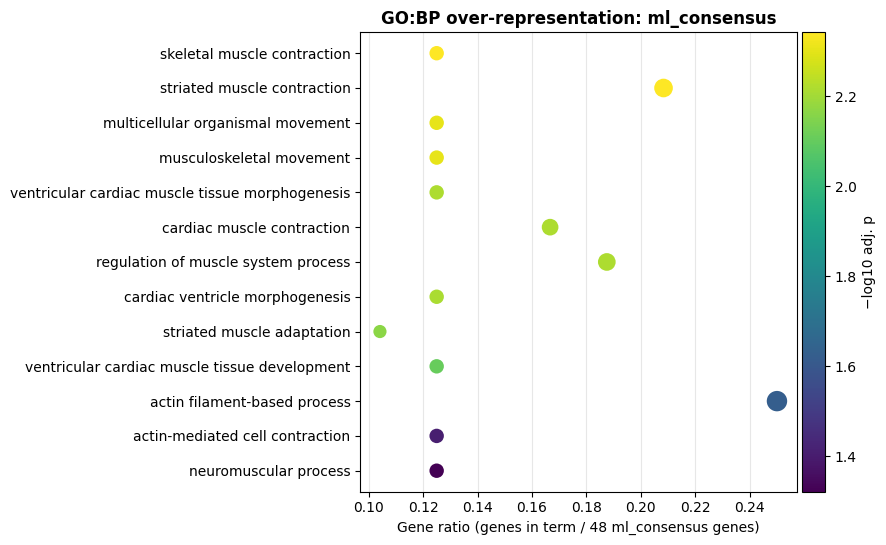


ml_importance — GO:BP  (8 terms shown)


term_id,description,set_size,nes,padj,leading edge,genes
GO:0010876,lipid localization,32,2.22,3.54e-02,21,"Apoa1, Apob, Slc4a1, Retn, Adipoq, Cidec, Rbp4, Cidea … (+13)"
GO:0051235,maintenance of location,27,2.33,3.54e-02,19,"Alb, Apoa1, Apob, F2, Cidec, Cidea, Mettl21c, Pln … (+11)"
GO:0051208,sequestering of calcium ion,11,2.42,3.62e-02,9,"F2, Mettl21c, Pln, Casq2, F2r, Gstm7, Gsto1, Ryr3 … (+1)"
GO:0051209,release of sequestered calcium ion into cytosol,11,2.42,3.62e-02,9,"F2, Mettl21c, Pln, Casq2, F2r, Gstm7, Gsto1, Ryr3 … (+1)"
GO:0051282,regulation of sequestering of calcium ion,11,2.42,3.62e-02,9,"F2, Mettl21c, Pln, Casq2, F2r, Gstm7, Gsto1, Ryr3 … (+1)"
GO:0051283,negative regulation of sequestering of calcium ion,11,2.42,3.62e-02,9,"F2, Mettl21c, Pln, Casq2, F2r, Gstm7, Gsto1, Ryr3 … (+1)"
GO:1903169,regulation of calcium ion transmembrane transport,18,2.28,4.91e-02,13,"Sln, Strit1, F2, Rrad, Mettl21c, Pln, Casq2, F2r … (+5)"
GO:0003009,skeletal muscle contraction,11,2.36,4.91e-02,6,"Myh3, Tnni1, Tnnc1, Tnnt1, Myh7, Strit1"


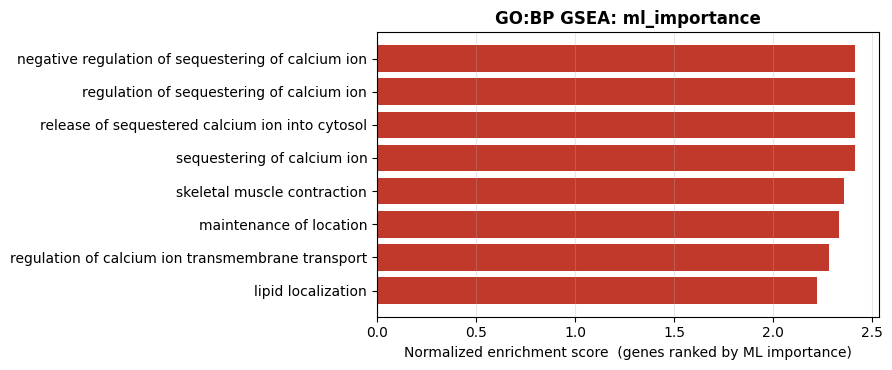

'if enrichment:\n    out_dir = globals().get("RESULTS_DIR", Path("."))\n    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")\n    fn = Path(out_dir) / f"go_enrichment_{stamp}.csv"\n    pd.DataFrame(enrichment["terms"]).assign(genes=lambda d: d["genes"].map("/".join)).to_csv(fn, index=False)\n    print(f"✓ Saved {len(enrichment[\'terms\'])} terms to {fn}")'

In [21]:
# %% [markdown]
# ## GO Enrichment
#
# Which biological processes are behind the genes each approach found?
#
# - **ORA (over-representation)** asks whether a gene list (ML consensus, DESeq2 significant, their overlap)
#   contains more genes from a GO term than expected by chance.
# - **GSEA** uses every gene, ranked: DESeq2 by direction and strength of change (signed −log10 p), and the ML
#   ensemble by mean importance rank. It finds terms whose genes cluster at the top (or, for DESeq2, the bottom)
#   of the ranking, without needing a cutoff.
#
# The background is the set of genes the pipeline analysed (the CV-filtered genes), not the whole genome, so
# terms aren't reported as enriched just because highly variable genes were selected.
# Settings come from `payload["config"]["enrichment"]`.

# %%
ENRICHMENT_DEFAULTS = {"enabled": False, "methods": ["ora", "gsea"], "ontologies": ["BP"],
                       "ora_lists": ["ml_consensus", "deseq2_significant", "overlap"],
                       "gsea_rankings": ["deseq2", "ml_importance"], "top_n_terms": 20}
enrich_cfg = {**ENRICHMENT_DEFAULTS, **payload["config"].get("enrichment", {})}
enrichment = None

def _build_enrichment_inputs():
    """Gene lists, rankings and universe from this run's results. Returns (lists, rankings, universe, notes)."""
    notes, lists, ranks = [], {}, {}
    de = deseq2_df.copy() if "deseq2_df" in globals() and not deseq2_df.empty else None
    padj_thr = globals().get("PADJ_THRESHOLD", 0.05)
    lfc_thr = globals().get("LOG2FC_THRESHOLD", 0.0)

    if de is not None:
        de["gene_id"] = de["gene_id"].astype(str)
        sig = de[(de["padj"] < padj_thr) & (de["log2_fold_change"].abs() > lfc_thr)]
        lists["deseq2_significant"] = sig["gene_id"].tolist()
        lists["deseq2_up"] = sig.loc[sig["log2_fold_change"] > 0, "gene_id"].tolist()
        lists["deseq2_down"] = sig.loc[sig["log2_fold_change"] < 0, "gene_id"].tolist()
        p = de["pvalue"].astype(float).clip(lower=1e-300)
        signed = np.sign(de["log2_fold_change"].astype(float)) * -np.log10(p)
        ok = np.isfinite(signed)
        ranks["deseq2"] = {"scores": dict(zip(de.loc[ok, "gene_id"], signed[ok].astype(float))), "score_type": "std"}
    else:
        notes.append("no DESeq2 results: skipping DESeq2 lists and ranking")

    if "consensus_genes" in globals():
        lists["ml_consensus"] = consensus_genes["gene"].astype(str).tolist()
    else:
        notes.append("no ML consensus genes: run the consensus cell first")
    if "rankings" in globals() and rankings:
        mean_rank = pd.concat(rankings.values(), axis=1).mean(axis=1).dropna()
        n = len(mean_rank)
        score = (n - mean_rank + 1) / n                     # best gene ~1, worst ~0; all positive
        ranks["ml_importance"] = {"scores": {str(g): float(s) for g, s in score.items()}, "score_type": "pos"}

    if "deseq2_significant" in lists and "ml_consensus" in lists:
        lists["overlap"] = (cmp["overlap"] if "cmp" in globals()
                            else sorted(set(lists["ml_consensus"]) & set(lists["deseq2_significant"])))

    if de is not None:
        universe = de["gene_id"].tolist()                   # the genes both analyses were given
    elif "ml_importance" in ranks:
        universe = list(ranks["ml_importance"]["scores"])
    else:
        universe = []
    return lists, ranks, universe, notes


if not result:
    print("Run the pipeline first")
elif not enrich_cfg["enabled"]:
    print('Enrichment is off. Set "enrichment": {"enabled": True, ...} in the config cell to run it.')
else:
    lists, ranks, universe, notes = _build_enrichment_inputs()
    cfg = dict(enrich_cfg)
    # Drop anything this run couldn't produce, rather than failing the whole request
    if "ora" in cfg["methods"]:
        unavailable = [n for n in cfg["ora_lists"] if n not in lists]
        cfg["ora_lists"] = [n for n in cfg["ora_lists"] if n in lists]
        notes += [f"ORA on '{n}' skipped: not available in this run" for n in unavailable]
    if "gsea" in cfg["methods"]:
        unavailable = [n for n in cfg["gsea_rankings"] if n not in ranks]
        cfg["gsea_rankings"] = [n for n in cfg["gsea_rankings"] if n in ranks]
        notes += [f"GSEA on '{n}' skipped: not available in this run" for n in unavailable]
    cfg["methods"] = [m for m in cfg["methods"]
                      if (m == "ora" and cfg["ora_lists"]) or (m == "gsea" and cfg["gsea_rankings"])]
    for n in notes:
        print("Note:", n)

    if not cfg["methods"] or not universe:
        print("Nothing to run for enrichment.")
    else:
        body = {"config": cfg, "universe": universe,
                "gene_lists": {n: lists[n] for n in cfg["ora_lists"]} if "ora" in cfg["methods"] else {},
                "rankings": {n: ranks[n] for n in cfg["gsea_rankings"]} if "gsea" in cfg["methods"] else {},
                "analysis_id": (result or {}).get("pipeline_id")}
        sizes = ", ".join(f"{n}: {len(g)}" for n, g in body["gene_lists"].items())
        print(f"Running GO {'/'.join(cfg['ontologies'])} enrichment ({', '.join(cfg['methods'])}) "
              f"on {len(universe)} background genes. Lists: {sizes or 'none'}. "
              f"Rankings: {', '.join(body['rankings']) or 'none'}.")
        print("This can take a few minutes (merging similar GO terms is the slow part)...")
        try:
            r = requests.post(f"{ORCHESTRATION_URL}/api/enrichment", json=body, timeout=1800)
            if r.status_code != 200:
                print(f"✗ Enrichment failed ({r.status_code}): {r.json().get('detail', r.text)[:800]}")
            else:
                enrichment = r.json()
                print(f"✓ Done: {len(enrichment['terms'])} enriched terms (organism: {enrichment['organism']})")
        except requests.exceptions.RequestException as e:
            print(f"✗ Couldn't reach the backend for enrichment: {e}")

if enrichment:
    summary_tbl = pd.DataFrame(enrichment["summaries"])
    display(summary_tbl.rename(columns={"n_input": "genes in", "n_mapped": "mapped to GO", "n_terms": "terms"}))

# %%
# Over-representation results: top terms per gene list
def _short_genes(genes, k=8):
    return ", ".join(genes[:k]) + (f" … (+{len(genes) - k})" if len(genes) > k else "")

if enrichment:
    terms = pd.DataFrame(enrichment["terms"])
    top_n = enrich_cfg.get("top_n_terms", 20)
    ora = terms[terms["method"] == "ora"] if not terms.empty else terms
    if ora.empty:
        print("No GO terms passed the cutoffs in the over-representation analysis.")
    for (name, ont), grp in (ora.groupby(["analysis", "ontology"], sort=False) if not ora.empty else []):
        grp = grp.sort_values("padj").head(top_n).copy()
        list_size = int(grp["gene_ratio"].iloc[0].split("/")[1])
        grp["ratio"] = grp["count"] / list_size
        print(f"\n{name} — GO:{ont}  ({len(grp)} of {int((ora['analysis'] == name).sum())} terms shown)")
        display(grp[["term_id", "description", "count", "gene_ratio", "bg_ratio", "padj", "genes"]]
                .assign(genes=grp["genes"].map(_short_genes))
                .style.format({"padj": "{:.2e}"}).hide(axis="index"))

        g = grp.iloc[::-1]
        fig, ax = plt.subplots(figsize=(9, max(2.5, 0.35 * len(g) + 1)))
        sc = ax.scatter(g["ratio"], g["description"].str.slice(0, 60), s=g["count"] * 18,
                        c=-np.log10(g["padj"].clip(lower=1e-300)), cmap="viridis", edgecolor="none")
        cb = fig.colorbar(sc, ax=ax, pad=0.01); cb.set_label("−log10 adj. p")
        ax.set_xlabel(f"Gene ratio (genes in term / {list_size} {name} genes)")
        ax.set_title(f"GO:{ont} over-representation: {name}", fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout(); plt.show()

# %%
# GSEA results: terms at the top (and bottom) of each ranking
if enrichment:
    gsea = terms[terms["method"] == "gsea"] if not terms.empty else terms
    if gsea.empty:
        print("No GO terms passed the cutoff in GSEA.")
    for (name, ont), grp in (gsea.groupby(["analysis", "ontology"], sort=False) if not gsea.empty else []):
        signed = (grp["nes"] < 0).any()
        if signed:   # show the strongest terms in each direction
            up = grp[grp["nes"] > 0].sort_values("padj").head(top_n // 2)
            down = grp[grp["nes"] < 0].sort_values("padj").head(top_n - len(up))
            grp = pd.concat([up, down])
        else:
            grp = grp.sort_values("padj").head(top_n)
        grp = grp.sort_values("nes")
        print(f"\n{name} — GO:{ont}  ({len(grp)} terms shown)")
        display(grp.sort_values("padj")[["term_id", "description", "set_size", "nes", "padj", "count", "genes"]]
                .assign(genes=grp["genes"].map(_short_genes))
                .rename(columns={"count": "leading edge"})
                .style.format({"nes": "{:.2f}", "padj": "{:.2e}"}).hide(axis="index"))

        fig, ax = plt.subplots(figsize=(9, max(2.5, 0.35 * len(grp) + 1)))
        colors = ["#c0392b" if v > 0 else "#2471a3" for v in grp["nes"]]
        ax.barh(grp["description"].str.slice(0, 60), grp["nes"], color=colors)
        ax.axvline(0, color="grey", lw=0.8)
        if name == "deseq2":
            fl = payload["config"].get("factor_values") or ["control", "treatment"]
            ax.set_xlabel(f"Normalized enrichment score  (red: higher in {fl[-1]}, blue: higher in {fl[0]})")
        else:
            ax.set_xlabel("Normalized enrichment score  (genes ranked by ML importance)")
        ax.set_title(f"GO:{ont} GSEA: {name}", fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout(); plt.show()

# %%
# Save all enriched terms
'''if enrichment:
    out_dir = globals().get("RESULTS_DIR", Path("."))
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    fn = Path(out_dir) / f"go_enrichment_{stamp}.csv"
    pd.DataFrame(enrichment["terms"]).assign(genes=lambda d: d["genes"].map("/".join)).to_csv(fn, index=False)
    print(f"✓ Saved {len(enrichment['terms'])} terms to {fn}")'''

## Save Results

In [19]:
'''if result:
    import os
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    filename = f"{OUTPUT_DIR}/pipeline_results_{timestamp}.json"

    with open(filename, 'w') as f:
        json.dump(result, f, indent=2, default=str)

    print(f"✓ Results saved to {filename}")

    # Save ensemble metrics
    train = result.get('training_results', {})
    test_metrics = train.get('test_metrics', {})
    models = test_metrics.get('models', [])

    if models:
        # Create metrics DataFrame for all models
        metrics_data = []
        for model in models:
            metrics_data.append({
                'Algorithm': model.get('algorithm', ''),
                'Accuracy': model.get('accuracy', 0),
                'Precision': model.get('precision', 0),
                'Recall': model.get('recall', 0),
                'F1_Score': model.get('f1_score', 0)
            })

        metrics_df = pd.DataFrame(metrics_data)
        csv_file = f"{OUTPUT_DIR}/ensemble_metrics_{timestamp}.csv"
        metrics_df.to_csv(csv_file, index=False)
        print(f"✓ Ensemble metrics saved to {csv_file}")

    if "consensus_df" in globals():
        consensus_df.to_csv(f"{OUTPUT_DIR}/consensus_genes_{timestamp}.csv", index=False)
        print(f"✓ Consensus gene votes saved to consensus_genes_{timestamp}.csv")
    if "cmp" in globals():
        cmp["table"].to_csv(f"{OUTPUT_DIR}/gene_comparison_{timestamp}.csv", index=False)
        print(f"✓ ML vs DESeq2 comparison saved to gene_comparison_{timestamp}.csv")
else:
    print("Run pipeline first")'''

'if result:\n    import os\n    os.makedirs(OUTPUT_DIR, exist_ok=True)\n    filename = f"{OUTPUT_DIR}/pipeline_results_{timestamp}.json"\n\n    with open(filename, \'w\') as f:\n        json.dump(result, f, indent=2, default=str)\n\n    print(f"✓ Results saved to {filename}")\n\n    # Save ensemble metrics\n    train = result.get(\'training_results\', {})\n    test_metrics = train.get(\'test_metrics\', {})\n    models = test_metrics.get(\'models\', [])\n\n    if models:\n        # Create metrics DataFrame for all models\n        metrics_data = []\n        for model in models:\n            metrics_data.append({\n                \'Algorithm\': model.get(\'algorithm\', \'\'),\n                \'Accuracy\': model.get(\'accuracy\', 0),\n                \'Precision\': model.get(\'precision\', 0),\n                \'Recall\': model.get(\'recall\', 0),\n                \'F1_Score\': model.get(\'f1_score\', 0)\n            })\n\n        metrics_df = pd.DataFrame(metrics_data)\n        csv_file 

In [20]:
# time the notebook
import datetime
end_time = datetime.datetime.now()
print('notebook end time: ', end_time.strftime('%Y-%m-%d %H:%M:%S'))

print('notebook runtime: ', end_time - start_time)
#

notebook end time:  2026-10-24 22:20:44
notebook runtime:  0:00:47.803703
